# 01 · MVTec AD dataset exploration

**Goal:** understand the data *before* any model sees it. No model is trained in this notebook.

We look at three categories: `bottle`, `hazelnut` and `carpet`. By the end we will know how the dataset is organised, how many normal and defective images there are, which defect types exist, what the images and masks look like, and we will have written a statistics report to `reports/`.

**Prerequisite:** MVTec AD placed under `data/mvtec_ad/` (see `docs/dataset.md`), or point the `INSPECTAI_DATA_ROOT` environment variable at it. Install notebook extras with `pip install -r requirements-notebooks.txt`.

In [1]:
import os
import sys
from pathlib import Path

# Make the repo importable whether the notebook is started from the repo root or notebooks/
REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO_ROOT))

DATA_ROOT = Path(os.environ.get("INSPECTAI_DATA_ROOT", REPO_ROOT / "data" / "mvtec_ad"))
if not DATA_ROOT.is_dir():
    raise FileNotFoundError(
        f"MVTec AD not found at {DATA_ROOT}. See docs/dataset.md for download and placement instructions, "
        "or set the INSPECTAI_DATA_ROOT environment variable."
    )
print("Data root:", DATA_ROOT)

import matplotlib.pyplot as plt

from inspectai.data import FOCUS_CATEGORIES, index_category, read_image_info, load_image, load_mask, validate_category
from inspectai.data.stats import dataset_statistics, write_report
from inspectai.data.viz import plot_category_samples, overlay_mask
import numpy as np

CATEGORIES = list(FOCUS_CATEGORIES)  # bottle, hazelnut, carpet
print("Categories:", CATEGORIES)

Data root: ../data/mvtec_ad


Categories: ['bottle', 'hazelnut', 'carpet']


## 1 · How MVTec AD is organised

MVTec AD is a benchmark for **unsupervised anomaly detection** in industrial inspection. It has 15 categories: 10 *objects* (e.g. `bottle`, `hazelnut`) and 5 *textures* (e.g. `carpet`).

The key design idea: **the training set contains only normal ("good") images.** Defects only appear in the test set. A model must learn what "normal" looks like and flag anything that deviates, without ever having seen a defect. This is why keeping train and test strictly separate matters so much here.

```
<root>/<category>/
    train/good/                      normal images only  (used for training)
    test/good/                       normal images       (evaluation)
    test/<defect_type>/              defective images    (evaluation)
    ground_truth/<defect_type>/      pixel-level masks, one per defective test image,
                                     named <image_stem>_mask.png
```

Two kinds of labels exist, and we keep them **separate**:

| Label | Granularity | Where it comes from |
|---|---|---|
| Image-level | one value per image: normal (0) / defective (1) | the folder name (`good` vs a defect name) |
| Pixel-level | one value per pixel: normal (0) / defective (255 in the file) | the mask PNG in `ground_truth/` |

Normal images have **no** mask file. The data is released under CC BY-NC-SA 4.0 (non-commercial use).

In [2]:
def show_tree(category: str, max_files: int = 2):
    base = DATA_ROOT / category
    print(base.name + "/")
    for top in sorted(p for p in base.iterdir() if p.is_dir() and not p.name.startswith(".")):
        print(f"  {top.name}/")
        for sub in sorted(p for p in top.iterdir() if p.is_dir() and not p.name.startswith(".")):
            files = sorted(f.name for f in sub.iterdir() if f.is_file() and not f.name.startswith("."))
            shown = ", ".join(files[:max_files]) + (", ..." if len(files) > max_files else "")
            print(f"    {sub.name}/  ({len(files)} files)  {shown}")

show_tree("bottle")

bottle/
  ground_truth/
    broken_large/  (20 files)  000_mask.png, 001_mask.png, ...
    broken_small/  (22 files)  000_mask.png, 001_mask.png, ...
    contamination/  (21 files)  000_mask.png, 001_mask.png, ...
  test/
    broken_large/  (20 files)  000.png, 001.png, ...
    broken_small/  (22 files)  000.png, 001.png, ...
    contamination/  (21 files)  000.png, 001.png, ...
    good/  (20 files)  000.png, 001.png, ...
  train/
    good/  (209 files)  000.png, 001.png, ...


## 2 · Normal vs defective counts

We index each category/split with `index_category`, which returns a sorted list of `Sample` records (image path, image-level `label`, `defect_type`, and — for defective images — the mask path).

In [3]:
rows = []
for cat in CATEGORIES:
    train = index_category(DATA_ROOT, cat, "train")
    test = index_category(DATA_ROOT, cat, "test")
    n_good = sum(s.label == 0 for s in test)
    n_def = sum(s.label == 1 for s in test)
    rows.append((cat, len(train), n_good, n_def, n_def / len(test)))

print(f"{'category':<10}{'train(normal)':>14}{'test normal':>13}{'test defective':>16}{'defect share':>14}")
for cat, tr, g, d, r in rows:
    print(f"{cat:<10}{tr:>14}{g:>13}{d:>16}{r:>13.1%}")

# Sanity check on the core MVTec property: no defects in training data
for cat in CATEGORIES:
    assert all(s.label == 0 for s in index_category(DATA_ROOT, cat, "train")), cat
print("\nTrain splits contain only normal images: OK")

category   train(normal)  test normal  test defective  defect share
bottle               209           20              63        75.9%
hazelnut             391           40              70        63.6%
carpet               280           28              89        76.1%

Train splits contain only normal images: OK


Notice that the test set is much smaller than the training set, and is dominated by **defective** images — the opposite of the training distribution. Accuracy would be a misleading metric here; later stages will use threshold-free metrics such as image-level AUROC.

## 3 · Defect categories

In [4]:
from collections import Counter

for cat in CATEGORIES:
    test = index_category(DATA_ROOT, cat, "test")
    counts = Counter(s.defect_type for s in test if s.is_defective)
    print(f"{cat}: {len(counts)} defect types")
    for name, n in sorted(counts.items()):
        print(f"    {name:<22}{n:>3} images")

bottle: 3 defect types
    broken_large           20 images
    broken_small           22 images
    contamination          21 images
hazelnut: 4 defect types
    crack                  18 images
    cut                    17 images
    hole                   18 images
    print                  17 images
carpet: 5 defect types
    color                  19 images
    cut                    17 images
    hole                   17 images
    metal_contamination    17 images
    thread                 19 images


## 4 · Image dimensions, formats and colour modes

We read only the image **headers** here (`deep=False`), which is fast and does not decode pixels.

In [5]:
for cat in CATEGORIES:
    infos = [read_image_info(s.image_path, deep=False)
             for split in ("train", "test") for s in index_category(DATA_ROOT, cat, split)]
    sizes = Counter(f"{i.width}x{i.height}" for i in infos)
    modes = Counter(i.mode for i in infos)
    fmts = Counter(i.format for i in infos)
    print(f"{cat:<9} sizes={dict(sizes)}  modes={dict(modes)}  formats={dict(fmts)}")

bottle    sizes={'900x900': 292}  modes={'RGB': 292}  formats={'PNG': 292}


hazelnut  sizes={'1024x1024': 501}  modes={'RGB': 501}  formats={'PNG': 501}


carpet    sizes={'1024x1024': 397}  modes={'RGB': 397}  formats={'PNG': 397}


Pillow reports `(width, height)`; arrays and tensors use `(height, width)`. The mode `RGB` means 3 channels of 8-bit values (0–255); `L` means a single grayscale channel. If a category contained grayscale images, `load_image` converts them to RGB so every sample has 3 channels.

## 5 · Validation: missing files and corrupted images

`validate_category(..., check_images=True)` fully **decodes** every image and mask and checks that: every defective image has a mask, no mask is orphaned, nothing is truncated/corrupted, and each mask has the same size as its image.

In [6]:
for cat in CATEGORIES:
    r = validate_category(DATA_ROOT, cat, check_images=True)
    status = "OK" if r.ok else f"{r.n_problems} PROBLEM(S)"
    print(f"{cat:<9} {status}  ({r.n_images_checked} images decoded)")
    if not r.ok:
        print("   ", r.to_dict())

bottle    OK  (292 images decoded)


hazelnut  OK  (501 images decoded)


carpet    OK  (397 images decoded)


## 6 · Visualising normal images, defective images and ground-truth masks

Each figure shows a row of normal training images, then one row per defect type: the defective image, its ground-truth mask (white = defective pixels) and the mask overlaid in red. These are the **original** full-resolution images; nothing is resized or modified.

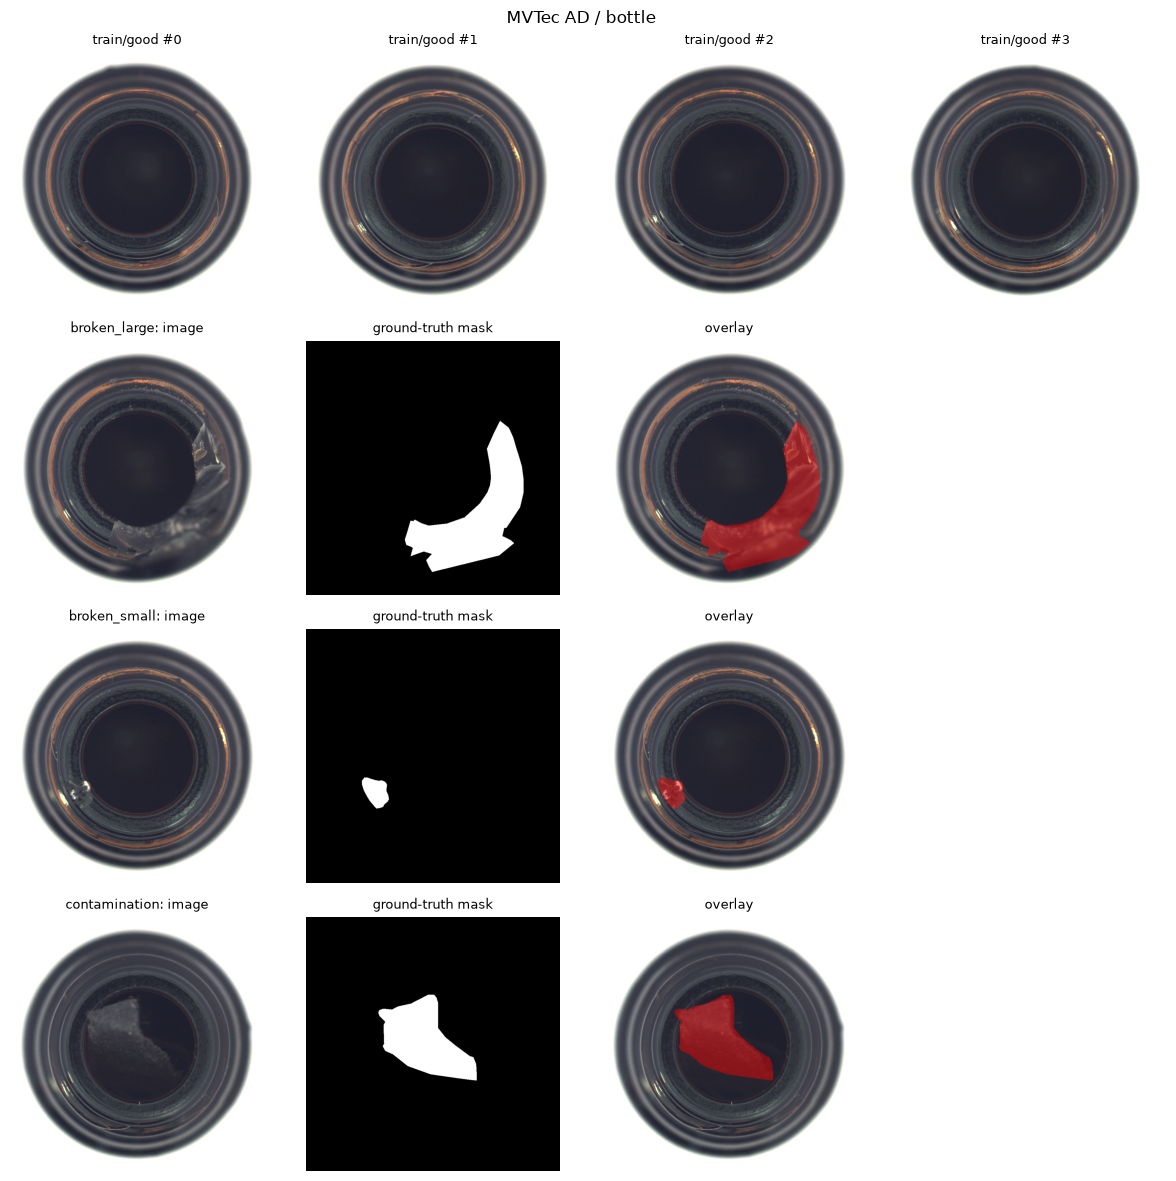

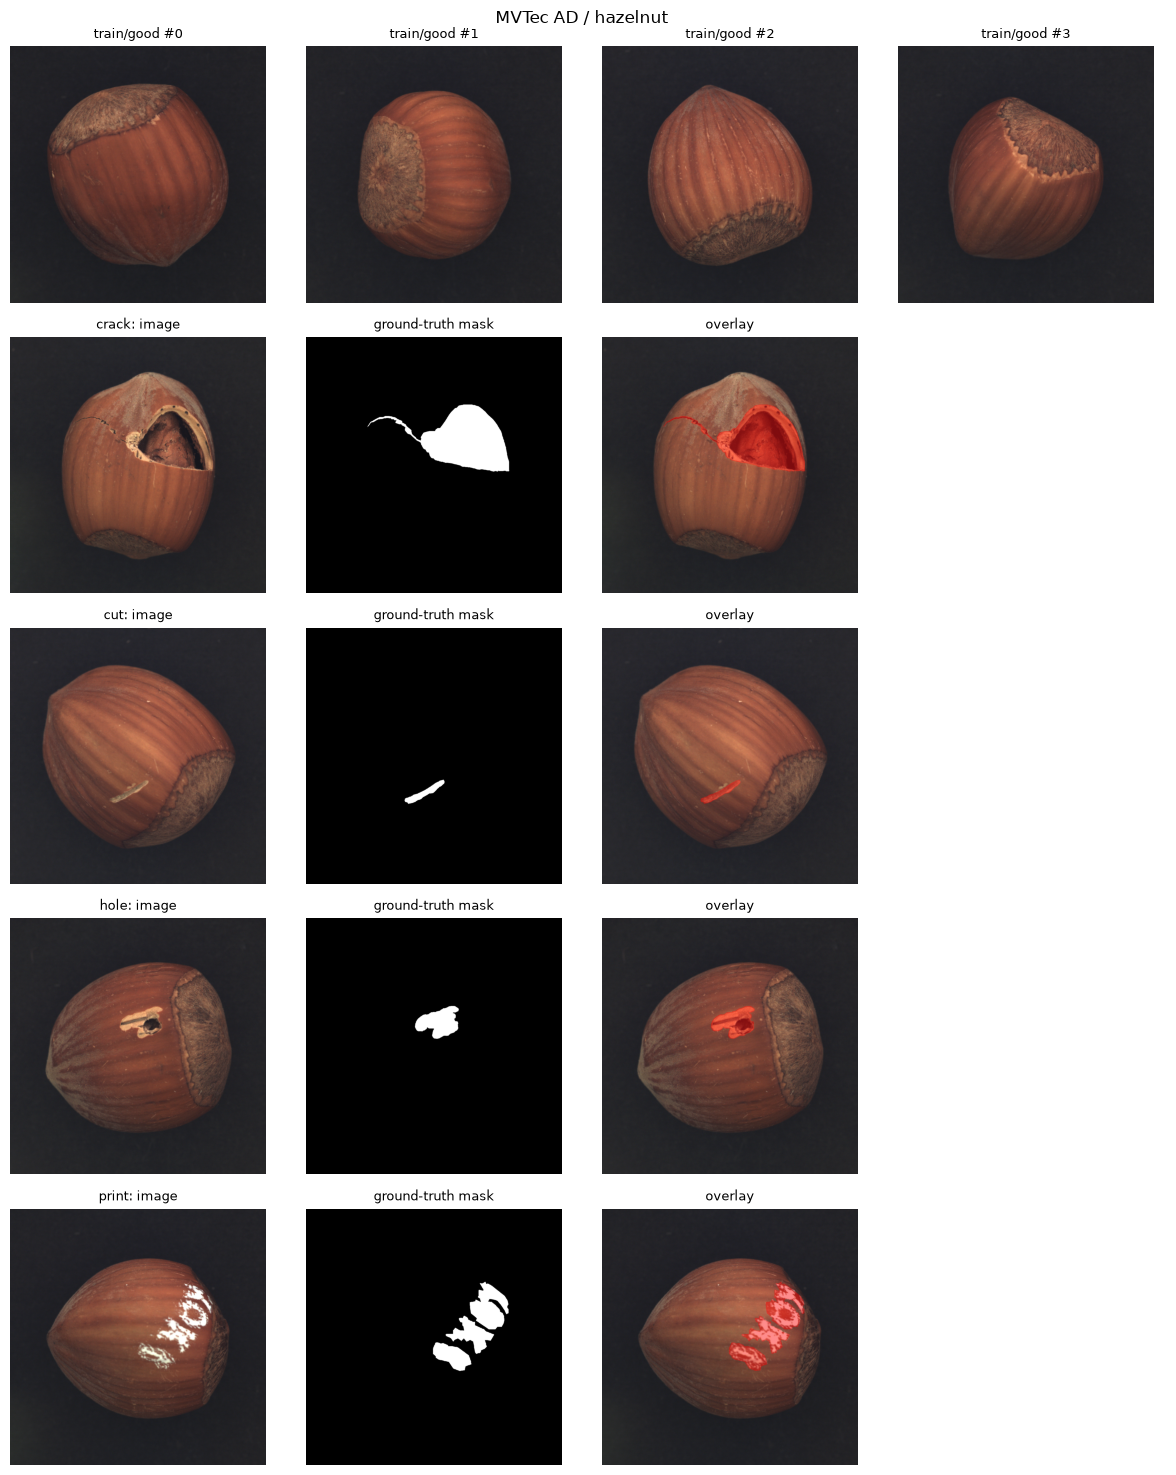

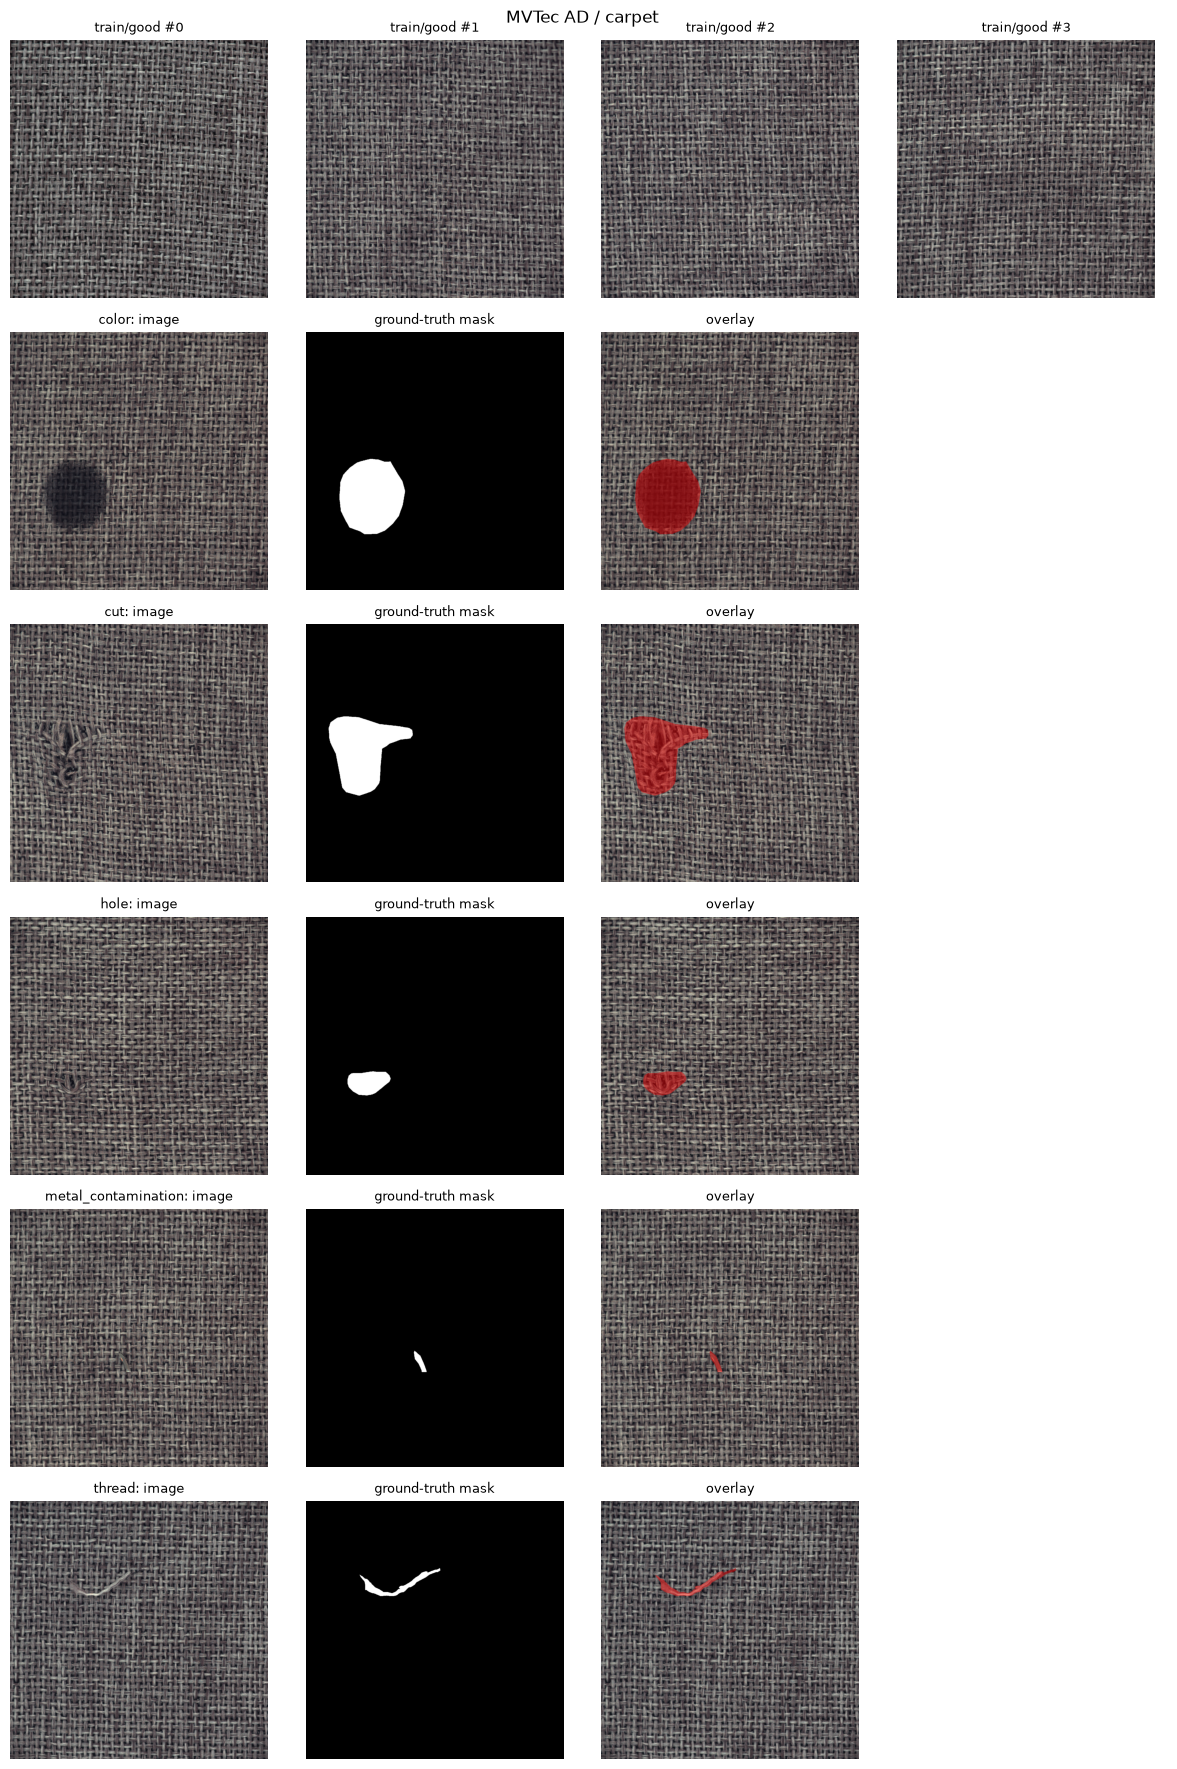

In [7]:
for cat in CATEGORIES:
    fig = plot_category_samples(DATA_ROOT, cat, n_normal=4, per_defect=1)
    plt.show()

## 7 · Pixel-level labels: how big are the defects?

Masks tell us how much of an image is defective. Small defects are harder to detect and affect how aggressively we may later downsample images.

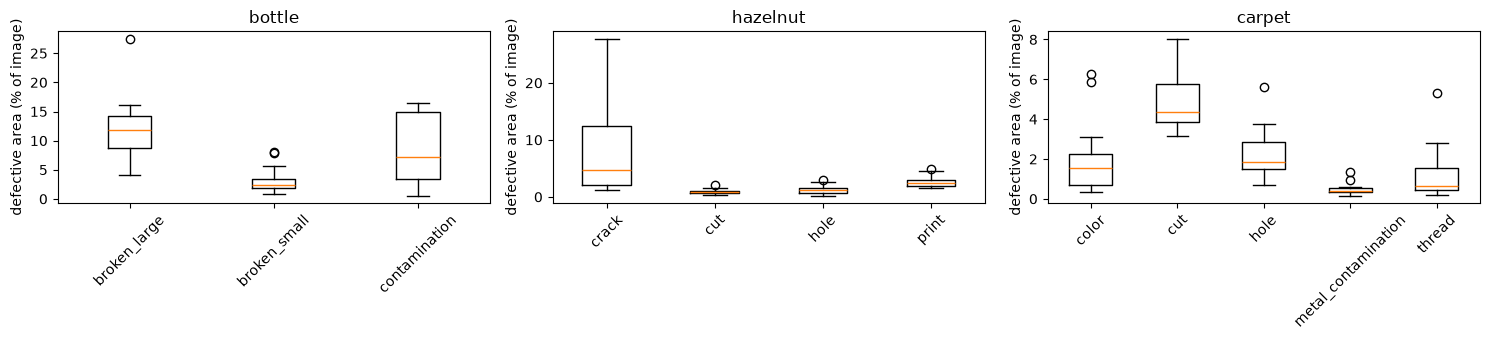

mask shape: (900, 900) dtype: uint8 unique values: [  0 255]


In [8]:
fig, axes = plt.subplots(1, len(CATEGORIES), figsize=(5 * len(CATEGORIES), 3.5), squeeze=False)
for ax, cat in zip(axes[0], CATEGORIES):
    fr = {}
    for s in index_category(DATA_ROOT, cat, "test"):
        if s.is_defective:
            m = np.asarray(load_mask(s.mask_path))
            fr.setdefault(s.defect_type, []).append((m > 0).mean() * 100)
    ax.boxplot(list(fr.values()))
    ax.set_xticklabels(list(fr.keys()))
    ax.set_title(cat)
    ax.set_ylabel("defective area (% of image)")
    ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
plt.show()

# Raw mask values: binary 0/255 in a single channel
s = next(s for s in index_category(DATA_ROOT, CATEGORIES[0], "test") if s.is_defective)
m = np.asarray(load_mask(s.mask_path))
print("mask shape:", m.shape, "dtype:", m.dtype, "unique values:", np.unique(m))

## 8 · Dataset statistics report

This computes everything above (plus per-category pixel mean/std, **from training images only**) and writes `reports/dataset_statistics.json` and `reports/dataset_statistics.md`. The same report can be produced from the command line with `python scripts/dataset_report.py`.

In [9]:
stats = dataset_statistics(DATA_ROOT, CATEGORIES, pixel_stats=True, root_label="data/mvtec_ad")
json_path, md_path = write_report(stats, REPO_ROOT / "reports")
print("Wrote", json_path.relative_to(REPO_ROOT))
print("Wrote", md_path.relative_to(REPO_ROOT))
print()
print(md_path.read_text())

Wrote reports/dataset_statistics.json
Wrote reports/dataset_statistics.md

# MVTec AD statistics report

Generated: 2026-11-01T09:08:20+00:00  
Data root: `data/mvtec_ad`

## Summary

| Category | Train (normal) | Test normal | Test defective | Defect types | Image size(s) | Mean defect area | Problems |
|---|---:|---:|---:|---:|---|---:|---:|
| bottle | 209 | 20 | 63 | 3 | 900x900 | 7.62% | 0 |
| hazelnut | 391 | 40 | 70 | 4 | 1024x1024 | 3.35% | 0 |
| carpet | 280 | 28 | 89 | 5 | 1024x1024 | 2.11% | 0 |

## bottle

- Train: 209 images (all normal)
- Test: 83 images — 20 normal, 63 defective (75.9% defective)
- Defect types: broken_large (20), broken_small (22), contamination (21)
- Image formats: PNG (292); modes: RGB (292); sizes: 900x900 (292)
- Masks: 63 (formats PNG (63), modes L (63)), empty masks: 0

| Defect type | Images | Min area | Median | Mean | Max |
|---|---:|---:|---:|---:|---:|
| broken_large | 20 | 4.09% | 11.87% | 11.70% | 27.42% |
| broken_small | 22 | 0.88% | 2.44

## Takeaways

* Training data is normal-only; evaluation data mixes normal and defective images, with defect share and defect types varying by category (see the tables above).
* Image-level labels (from folder names) and pixel-level masks (from `ground_truth/`) are separate sources of truth; normal images have no mask.
* All files were fully decoded and cross-checked (see section 5). Any problems would be listed there and in the JSON report.
* Normalisation statistics must come from the training split only. They are in the report under `train_pixel_stats`.

Next notebook: `02_image_preprocessing.ipynb` turns these images into tensors and batches.